# Behavioural analysis 003: step timing

## Imports

In [2]:
%load_ext autoreload
%autoreload 2
import sys

sys.path.append('../../')

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as sgnl

import tools.dsp as dsp
import tools.viz.utilityTools as vizutils

import bhv
from bhv import ACCENT, EXAMPLE, FS, NEUTRAL, ON, WIN

### Load bhv

In [4]:
CACHE = Path("/mnt/mouse-data-london/proc") / "cache" / "bhv"

SESSIONS_DPCA = [
    "M061_2025_03_04_10_00",
    "M061_2025_03_05_14_00",
    "M061_2025_03_06_14_00",
    "M062_2025_03_20_14_00",
    "M062_2025_03_21_14_00",
    "M078_2025_08_06_15_00",
    "M086_2025_12_10_15_00",
    "M103_2026_02_18_15_30",
    "M106_2026_02_25_15_00",
]

In [5]:
s = bhv.load_bhv_cache(SESSIONS_DPCA, CACHE)

## Perturb score vs. phase at perturb

### What the phase means: foot position over the gait cycle

In [ ]:
PH_LIMB, PH_REF, STEP = "left_foot", "hip_center", 5
bhv_rot = s[EXAMPLE]["bhv_rot"]
kps = [str(k) for k in s[EXAMPLE]["bhv_keypoints"]]

foot_rc, foot_vt = (bhv.rel_position(bhv_rot, PH_LIMB, ch=ch, keypoints=kps) for ch in (0, 1))
foot_rc_vel = np.gradient(foot_rc, axis=1) * FS

phases, rc, vt, rc_vel = [], [], [], []
for i, tr in enumerate(foot_rc):
    f0 = bhv.stride_frequency(tr)
    for end in range(WIN, ON + 1, STEP):
        phases.append(bhv.phase_at(tr, end, f0))
        rc.append(tr[end - 1])
        vt.append(foot_vt[i, end - 1])
        rc_vel.append(foot_rc_vel[i, end - 1])
phases, rc, vt, rc_vel = map(np.array, (phases, rc, vt, rc_vel))

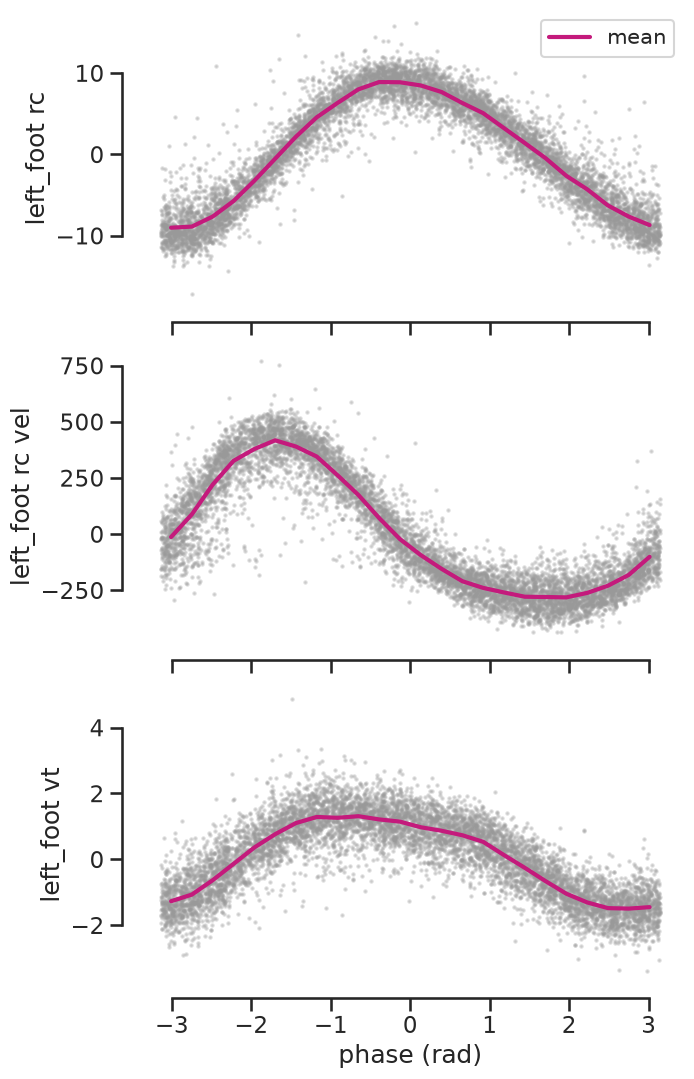

phase of the median rc maximum: -0.39 rad; minimum: -3.01 rad


In [114]:
bins = np.linspace(-np.pi, np.pi, 25)
mid = (bins[:-1] + bins[1:]) / 2
in_bin = [(phases >= lo_) & (phases < hi_) for lo_, hi_ in zip(bins[:-1], bins[1:])]
panels = [(rc, f"{PH_LIMB} rc"), (rc_vel, f"{PH_LIMB} rc vel"), (vt, f"{PH_LIMB} vt")]

with vizutils.apply_plot_style("talk"):
    fig, axs = plt.subplots(len(panels), 1, figsize=(7, 11), sharex=True)
    for ax, (y, label) in zip(axs, panels):
        ax.scatter(phases, y, s=3, color="0.6", alpha=0.3, rasterized=True)
        ax.plot(mid, [np.mean(y[m]) for m in in_bin], color=ACCENT, lw=3, label="mean")
        ax.set_ylabel(label)
    axs[0].legend(fontsize="small")
    axs[-1].set_xlabel("phase (rad)")
    plt.tight_layout()
plt.show()
med = np.array([np.mean(rc[m]) for m in in_bin])
print("phase of the median rc maximum:", round(float(mid[med.argmax()]), 2), "rad; minimum:", round(float(mid[med.argmin()]), 2), "rad")

### Perturb score (log-sum) vs. phase at the push

In [242]:
LOG_SUM, N_PERM = "perturb_score_log_sum", 1000

rng = np.random.default_rng(0)
score = {}
for sess, d in s.items():
    rc = bhv.rel_position(d["bhv_rot"], PH_LIMB, PH_REF, keypoints=d["bhv_keypoints"])
    ph, y, codes_ = bhv.phase_at_push(rc), d[LOG_SUM], d["codes"]
    ok = np.isfinite(y)
    score[sess] = dict(phase=ph[ok], y=y[ok], **bhv.circular_r2_test(ph[ok], y[ok], codes_[ok], N_PERM, rng))
    print(f"{sess}: n {ok.sum()}, R2 {score[sess]['r2']:.3f}, null 95th {score[sess]['null95']:.3f}, p {score[sess]['p']:.3f}")

r2s = np.array([v["r2"] for v in score.values()])
print(f"R2 median {np.median(r2s):.3f} [{r2s.min():.3f}, {r2s.max():.3f}]; p < 0.05 in {sum(v['p'] < 0.05 for v in score.values())}/{len(score)} sessions")

M061_2025_03_04_10_00: n 213, R2 0.003, null 95th 0.023, p 0.697
M061_2025_03_05_14_00: n 135, R2 0.007, null 95th 0.034, p 0.501
M061_2025_03_06_14_00: n 222, R2 0.000, null 95th 0.026, p 0.983
M062_2025_03_20_14_00: n 217, R2 0.001, null 95th 0.023, p 0.897
M062_2025_03_21_14_00: n 236, R2 0.004, null 95th 0.023, p 0.598
M078_2025_08_06_15_00: n 273, R2 0.025, null 95th 0.020, p 0.022
M086_2025_12_10_15_00: n 257, R2 0.000, null 95th 0.020, p 0.953
M103_2026_02_18_15_30: n 294, R2 0.003, null 95th 0.017, p 0.558
M106_2026_02_25_15_00: n 220, R2 0.006, null 95th 0.032, p 0.611
R2 median 0.003 [0.000, 0.025]; p < 0.05 in 1/9 sessions


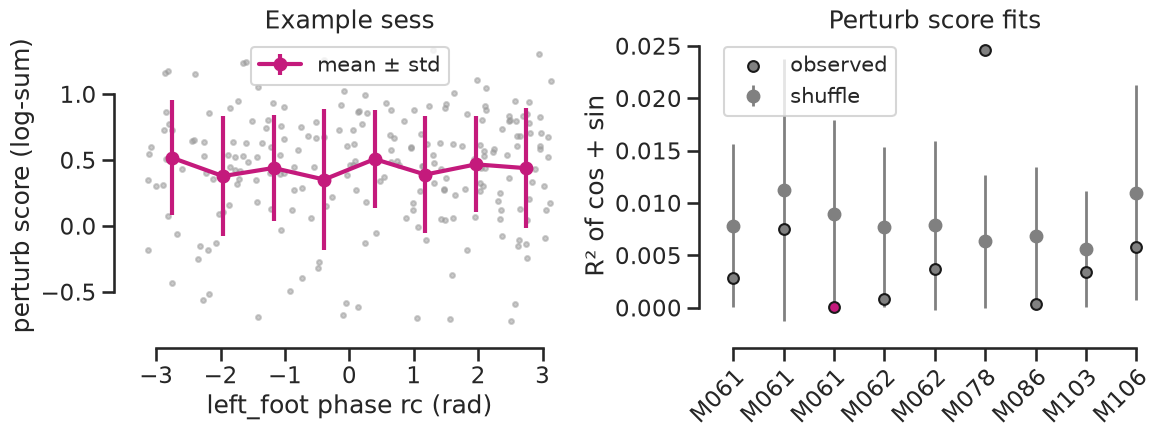

In [243]:
ex = score[EXAMPLE]
bins = np.linspace(-np.pi, np.pi, 9)
mid = (bins[:-1] + bins[1:]) / 2
grp = [ex["y"][(ex["phase"] >= lo_) & (ex["phase"] < hi_)] for lo_, hi_ in zip(bins[:-1], bins[1:])]

with vizutils.apply_plot_style("talk"):
    fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw=dict(width_ratios=[1, 1]))
    ax = axs[0]
    ax.scatter(ex["phase"], ex["y"], s=12, color="0.6", alpha=0.5)
    ax.errorbar(mid, [g.mean() for g in grp], yerr=[g.std(ddof=1) for g in grp], color=ACCENT, lw=3, marker="o", label="mean ± std")
    ax.set_xticks(np.arange(-3, 4))
    ax.set_xlabel(f"{PH_LIMB} phase rc (rad)")
    ax.set_ylabel("perturb score (log-sum)")
    ax.set_title(f"Example sess")
    ax.legend(fontsize="small")
    ax = axs[1]
    for j, (sess, v) in enumerate(score.items()):
        ax.errorbar(j, v["null_mean"], fmt='o', yerr=v["null_std"], color="0.5", lw=2, capsize=0, label="shuffle" if j == 0 else None)
        ax.scatter(j, v["r2"], s=60, color=ACCENT if sess == EXAMPLE else "0.5", edgecolor="k", zorder=3, label="observed" if j == 0 else None)
    ax.set_title(f"Perturb score fits")    
    ax.set_xticks(range(len(score)), [s_[:4] for s_ in score])
    ax.set_ylabel("R² of cos + sin")
    ax.legend(fontsize="small")
    plt.tight_layout()
ax.tick_params(axis="x", labelrotation=45)
plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
plt.show()

## Step timing

In [244]:
LIMB, TRIAL = "right_ankle", 106

X = s[EXAMPLE]["bhv_rot"][TRIAL]
t = (np.arange(len(X)) - ON) / FS
x = bhv.rel_position(X, LIMB, "hip_center")

f0 = bhv.stride_frequency(x)
lo, hi = np.percentile(x[:ON], [5, 95])
peaks, _ = sgnl.find_peaks(x, distance=int(0.6 * FS / f0), prominence=0.25 * (hi - lo))
touchdowns = t[peaks]

before, after = touchdowns[touchdowns < 0], touchdowns[touchdowns > 0]
T = np.median(np.diff(before[-4:]))
scheduled = before[-1] + T
delay = after[0] - scheduled
print(f"f0 {f0:.1f} Hz, T {1000 * T:.0f} ms, scheduled {1000 * scheduled:.0f} ms, actual {1000 * after[0]:.0f} ms, delay {1000 * delay:.0f} ms")

f0 6.4 Hz, T 160 ms, scheduled 150 ms, actual 170 ms, delay 20 ms


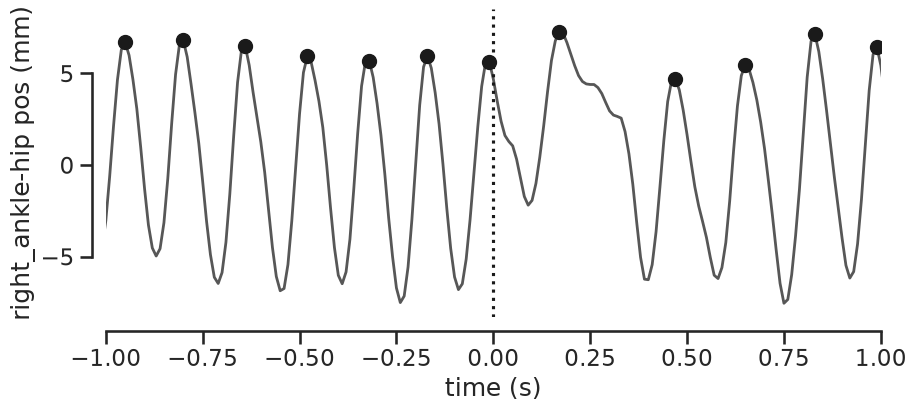

In [245]:
with vizutils.apply_plot_style("talk"):
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(t, x, color=NEUTRAL, lw=2)
    ax.plot(touchdowns, x[peaks], "o", color="k", ms=10, label="touchdown")
    ax.axvline(0, color="k", ls=":", label="push")
    ax.set_xlim(-1, 1)
    ax.set_xlabel("time (s)")
    ax.set_ylabel(f"{LIMB}-hip pos (mm)")
plt.show()

### Expected touchdown from a sine fit to the last 0.3 s before the push

In [246]:
phase, f_fit, b, mu, *_ = dsp.sinefit(x[ON - WIN:ON], f0, fs=FS)

tw = t - t[ON - 1]
expected = mu + b[0] + b[2] * np.cos(2 * np.pi * f_fit * tw) + b[3] * np.sin(2 * np.pi * f_fit * tw)

n = np.arange(-1, 20)
exp_td = (2 * np.pi * n - phase) / (2 * np.pi * f_fit) + t[ON - 1]
exp_after = exp_td[exp_td > 0][0]
print(f"fit {f_fit:.1f} Hz; expected touchdown {1000 * exp_after:.0f} ms, measured {1000 * after[0]:.0f} ms, "
      f"measured - expected {1000 * (after[0] - exp_after):.0f} ms")

fit 6.5 Hz; expected touchdown 141 ms, measured 170 ms, measured - expected 29 ms


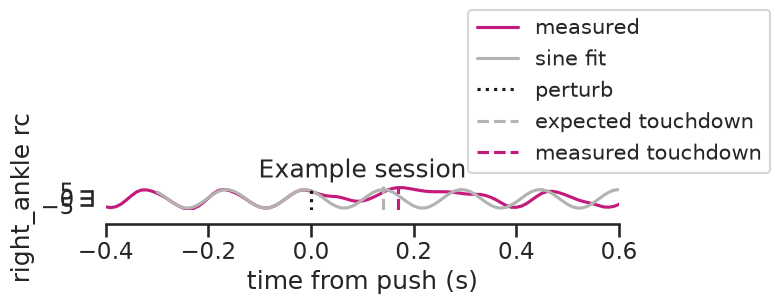

In [248]:
with vizutils.apply_plot_style("talk"):
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(t, x, color=ACCENT, label="measured")
    ax.plot(t[ON - WIN:], expected[ON - WIN:], color="0.7", label="sine fit")
    ax.axvline(0, color="k", ls=":", label="perturb")
    ax.axvline(exp_after, color="0.7", ls="--", label="expected touchdown")
    ax.axvline(after[0], color=ACCENT, ls="--", label="measured touchdown")
    ax.set_xlim(-0.4, 0.6)
    ax.set_xlabel("time from push (s)")
    ax.set_ylabel(f"{LIMB} rc")
    ax.legend(fontsize="small", loc="lower center", bbox_to_anchor=(1, 1.1))
    ax.set_title('Example session')
    plt.tight_layout()
plt.show()

### Touchdown delay vs. phase at the push

In [257]:
KP, REF = "right_foot", "hip_center"
session = EXAMPLE

d = bhv.delay_table(s[session]["bhv_rot"], KP, REF)
print(f"{session}: {len(d)} trials; delay NaN (stall / missed touchdown) push {d.delay_push.isna().mean():.2f}, running {d.delay_run.isna().mean():.2f}")

rng = np.random.default_rng(0)

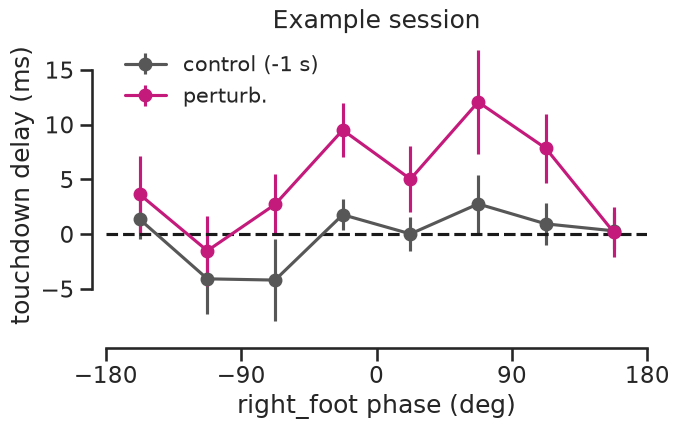

In [259]:
bins = np.linspace(-np.pi, np.pi, 9)
centres = np.rad2deg((bins[:-1] + bins[1:]) / 2)

with vizutils.apply_plot_style("talk"):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for which, color, label in (("run", NEUTRAL, "control (-1 s)"), ("push", ACCENT, "perturb.")):
        idx = np.digitize(d[f"phase_{which}"], bins) - 1
        per_bin = [d[f"delay_{which}"][idx == k].dropna().values for k in range(len(centres))]
        med = [np.median(v) if len(v) else np.nan for v in per_bin]
        err = [bhv.median_se(v, rng) for v in per_bin]
        ax.errorbar(centres, med, yerr=err, fmt="-o", color=color, capsize=0, label=label)
    ax.axhline(0, color="k", ls='--')
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_xlabel(f"{KP} phase (deg)")
    ax.set_ylabel("touchdown delay (ms)")
    ax.set_title(f"Example session")
    ax.legend(frameon=False, fontsize="small")
    plt.tight_layout()
plt.show()

In [272]:
BINS = 12

d_all = pd.concat([bhv.delay_table(s[sess]["bhv_rot"], KP, REF).assign(session=sess) for sess in SESSIONS_DPCA], ignore_index=True)
print(f"{len(d_all)} trials from {d_all.session.nunique()} sessions")

2067 trials from 9 sessions


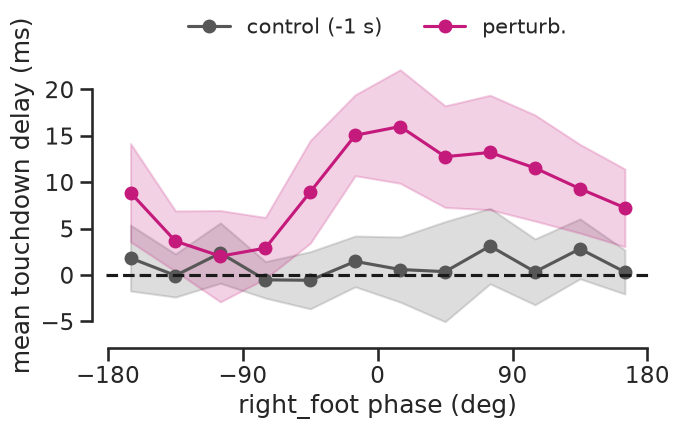

In [273]:
stat = np.std
means = {sess: bhv.get_mean_sess(d_all, sess, BINS) for sess in SESSIONS_DPCA}
mean_arr_push = np.array([means[sess]["push"] for sess in SESSIONS_DPCA])
mean_arr_run = np.array([means[sess]["run"] for sess in SESSIONS_DPCA])
edges = np.linspace(-np.pi, np.pi, BINS + 1)
centres = np.rad2deg((edges[:-1] + edges[1:]) / 2)

with vizutils.apply_plot_style("talk"):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    vizutils.shaded_errorbar(ax, centres, mean_arr_run.T, lineStat=np.mean, errorStat=stat, color=NEUTRAL, label="control (-1 s)", marker="o")
    vizutils.shaded_errorbar(ax, centres, mean_arr_push.T, lineStat=np.mean, errorStat=stat, color=ACCENT, label="perturb.", marker="o")
    ax.axhline(0, color="k", ls="--")
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_xlabel(f"{KP} phase (deg)")
    ax.set_ylabel("mean touchdown delay (ms)")
    ax.legend(fontsize="small", loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
    plt.tight_layout()
plt.show()

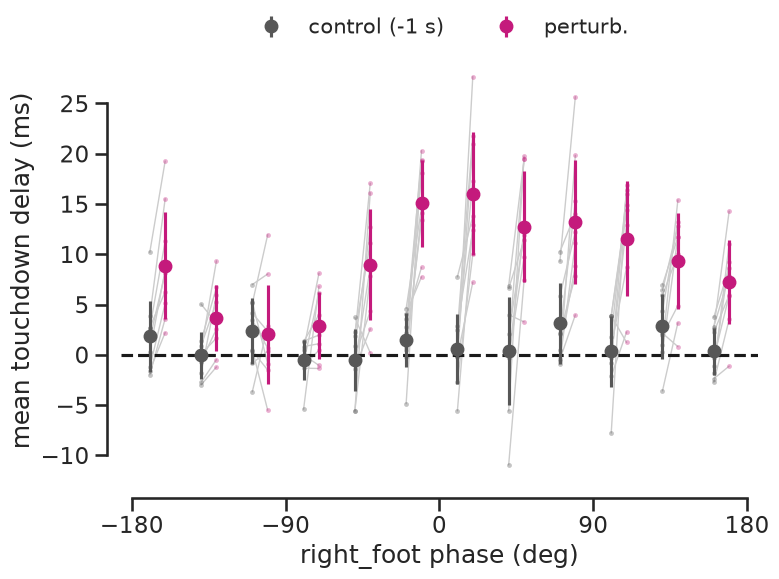

In [274]:
edges = np.linspace(-np.pi, np.pi, BINS + 1)
centres = np.rad2deg((edges[:-1] + edges[1:]) / 2)
shift = 0.15 * 360 / BINS
x_pair = np.array([centres - shift, centres + shift])
run_arr = np.array([means[sess]["run"] for sess in SESSIONS_DPCA])
push_arr = np.array([means[sess]["push"] for sess in SESSIONS_DPCA])

with vizutils.apply_plot_style("talk"):
    fig, ax = plt.subplots(figsize=(8, 6))
    for run_s, push_s in zip(run_arr, push_arr):
        ax.plot(x_pair, np.array([run_s, push_s]), color="0.8", lw=1, zorder=1)
    for arr, x, color, label in ((run_arr, x_pair[0], NEUTRAL, "control (-1 s)"), (push_arr, x_pair[1], ACCENT, "perturb.")):
        ax.scatter(np.tile(x, (len(arr), 1)), arr, s=12, color=color, alpha=0.35, zorder=2, lw=0)
        ax.errorbar(x, np.mean(arr, axis=0), yerr=np.nanstd(arr, axis=0), fmt="o", color=color, capsize=0, zorder=3, label=label)
    ax.axhline(0, color="k", ls="--")
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_xlabel(f"{KP} phase (deg)")
    ax.set_ylabel("mean touchdown delay (ms)")
    ax.legend(fontsize="small", loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
    plt.tight_layout()
plt.show()